In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

# PERSIAPAN

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Pada laporan praktikum, sisipkan penjelasan singkat mengenai *library* `sklearn` (ambil dari https://scikit-learn.org/stable/) pada **BAB 2** pada bagian metode yang melibatkannya.

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/MyDrive/sml') # ganti dengan folder hasil copy kalian

In [ ]:
df_full = pd.read_csv("email_campaign.csv")
df_full.head()

,CustId,PastPurchases,AvgOrderValue,EmailOpens90d,MobileUser,PromoOptIn,LoyaltyMember,Region,PreferredCategory,Response
0,1,5.0,408.97,6.0,0.0,No,0.0,Urban,Electronics,NoAction
1,2,3.0,187.94,10.0,1.0,No,0.0,Rural,Mixed,ClickOnly
2,3,1.0,126.54,0.0,1.0,NaN,1.0,Urban,Fashion,NoAction
3,4,3.0,191.40,0.0,0.0,Yes,0.0,Urban,Groceries,NoAction
4,5,9.0,354.34,11.0,1.0,Yes,1.0,Urban,Electronics,Purchase


Kasus ini memodelkan klasifikasi respons pelanggan (`NoAction`, `ClickOnly`, atau `Purchase`) terhadap satu kampanye email promosi pada sebuah toko online, dengan populasi berupa seluruh pelanggan yang menerima kampanye email tersebut dalam periode tertentu.
- `CustId`: nomor unik pengenal pelanggan
- `PastPurchases`: jumlah pesanan yang berhasil diselesaikan pelanggan dalam 12 bulan terakhir
- `AvgOrderValue`: rata-rata nilai transaksi per pesanan dalam 12 bulan terakhir (dalam ribu rupiah)
- `EmailOpens90d`: jumlah email marketing dari toko yang dibuka pelanggan dalam 90 hari terakhir
- `MobileUser`: apakah pelanggan lebih sering menggunakan aplikasi mobile dibandingkan website (`1` = ya atau `0` = tidak)
- `PromoOptIn`: status persetujuan pelanggan untuk menerima promosi (`Yes` = pernah menyetujui, `No` = tidak/ belum menyetujui)
- `LoyaltyMember`: keanggotaan pelanggan dalam program loyalti toko (`1` = anggota, `0` = bukan anggota)
* `Region`: tipe wilayah domisili pelanggan:
  - `Urban` = tinggal di area perkotaan padat,
  - `Suburban` = tinggal di area pinggiran kota, atau
  - `Rural` = tinggal di area pedesaan.
- `PreferredCategory`: kategori produk yang paling sering dibeli pelanggan:
  - `Fashion` = pakaian, sepatu, dan aksesoris,
  - `Electronics` = gadget, komputer, dan perangkat rumah tangga elektronik,
  - `Groceries` = makanan, minuman, dan bahan pokok, atau
  - `Mixed` = tidak ada satu kategori yang dominan.
- `Response`: respons pelanggan terhadap kampanye email promosi:
  - `NoAction` = pelanggan tidak membuka email sama sekali,
  - `ClickOnly` = pelanggan membuka dan/atau mengklik email tetapi tidak melakukan pembelian dari kampanye tersebut, atau
  - `Purchase` = pelanggan melakukan pembelian yang teratribusi pada kampanye setelah membuka/mengakses email).

Melihat struktur data mentah

In [ ]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustId             5250 non-null   int64  
 1   PastPurchases      4758 non-null   float64
 2   AvgOrderValue      4757 non-null   float64
 3   EmailOpens90d      4758 non-null   float64
 4   MobileUser         4764 non-null   float64
 5   PromoOptIn         4714 non-null   object 
 6   LoyaltyMember      4788 non-null   float64
 7   Region             4739 non-null   object 
 8   PreferredCategory  4737 non-null   object 
 9   Response           5250 non-null   object 
dtypes: float64(5), int64(1), object(4)
memory usage: 410.3+ KB


Pemilihan variabel

In [ ]:
df_full.columns

Index(['CustId', 'PastPurchases', 'AvgOrderValue', 'EmailOpens90d',
       'MobileUser', 'PromoOptIn', 'LoyaltyMember', 'Region',
       'PreferredCategory', 'Response'],
      dtype='object')

In [ ]:
df = df_full.copy()
df = df_full.drop(columns=['CustId'], axis=1)
df.head()

,PastPurchases,AvgOrderValue,EmailOpens90d,MobileUser,PromoOptIn,LoyaltyMember,Region,PreferredCategory,Response
0,5.0,408.97,6.0,0.0,No,0.0,Urban,Electronics,NoAction
1,3.0,187.94,10.0,1.0,No,0.0,Rural,Mixed,ClickOnly
2,1.0,126.54,0.0,1.0,NaN,1.0,Urban,Fashion,NoAction
3,3.0,191.40,0.0,0.0,Yes,0.0,Urban,Groceries,NoAction
4,9.0,354.34,11.0,1.0,Yes,1.0,Urban,Electronics,Purchase


Mempersingkat nama kolom

In [ ]:
df.columns = ['past', 'avg_order', 'opens', 'mobile', 'promo', 'loyalty', 'region', 'category', 'response']
df.head()

,past,avg_order,opens,mobile,promo,loyalty,region,category,response
0,5.0,408.97,6.0,0.0,No,0.0,Urban,Electronics,NoAction
1,3.0,187.94,10.0,1.0,No,0.0,Rural,Mixed,ClickOnly
2,1.0,126.54,0.0,1.0,NaN,1.0,Urban,Fashion,NoAction
3,3.0,191.40,0.0,0.0,Yes,0.0,Urban,Groceries,NoAction
4,9.0,354.34,11.0,1.0,Yes,1.0,Urban,Electronics,Purchase


Mengubah data kategorik yang terbaca numerik oleh Python

In [ ]:
df = df.copy()
for c in ['mobile', 'loyalty']:
    df[c] = df[c].astype("Int64").astype("object")

In [ ]:
df[['mobile', 'loyalty']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   mobile   4764 non-null   object
 1   loyalty  4788 non-null   object
dtypes: object(2)
memory usage: 82.2+ KB


# EXPLORATORY DATA ANALYSIS

### Ringkasan

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   past       4758 non-null   float64
 1   avg_order  4757 non-null   float64
 2   opens      4758 non-null   float64
 3   mobile     4764 non-null   object 
 4   promo      4714 non-null   object 
 5   loyalty    4788 non-null   object 
 6   region     4739 non-null   object 
 7   category   4737 non-null   object 
 8   response   5250 non-null   object 
dtypes: float64(3), object(6)
memory usage: 369.3+ KB


In [ ]:
df.describe(include = 'number')

,past,avg_order,opens
count,4758.000000,4757.000000,4758.000000
mean,5.160992,292.008644,5.944094
std,7.370701,213.204578,7.458372
min,0.000000,50.000000,0.000000
25%,2.000000,173.340000,2.000000
50%,3.000000,226.760000,4.000000
75%,6.000000,324.540000,8.000000
max,77.000000,2040.490000,72.000000


In [ ]:
df.describe(include = ['category', 'object'])

,mobile,promo,loyalty,region,category,response
count,4764,4714,4788,4739,4737,5250
unique,2,2,2,3,4,3
top,1,Yes,0,Urban,Fashion,NoAction
freq,2571,2444,3174,1868,1372,3253


## Visualisasi

### Univariat

Kategorik

Perbandingan Proporsi Pelanggan Menurut Respons


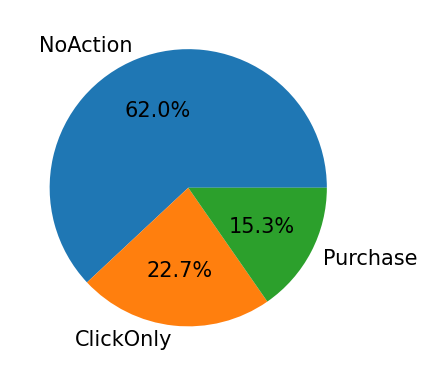

In [ ]:
print('Perbandingan Proporsi Pelanggan Menurut Respons')

plt.figure(figsize=(6,3), dpi=150)
df["response"].value_counts().plot(kind="pie", autopct="%.1f%%", ylabel="")
plt.show()

Berdasarkan pie chart di atas, proporsi variabel target **cenderung imbalanced**, sehingga **diperlukan penanganan imbalanced data**.

Proporsi Pelanggan Berdasarkan Status Keanggotaan


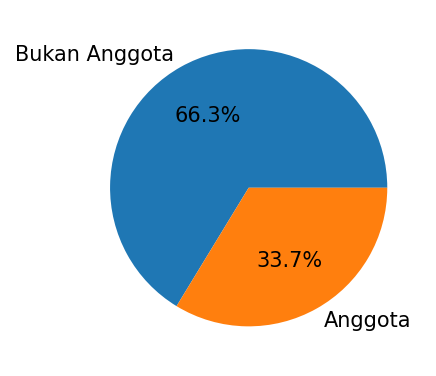

In [ ]:
print('Proporsi Pelanggan Berdasarkan Status Keanggotaan')

plt.figure(figsize=(6, 3), dpi=150)
df["loyalty"].map({0: "Bukan Anggota", 1: "Anggota"}) \
           .value_counts() \
           .plot(kind="pie", autopct="%.1f%%", ylabel="")
plt.show()

Numerik

Sebaran Rata-Rata Nilai Transaksi Pelanggan per Pesanan dalam 12 Bulan Terakhir


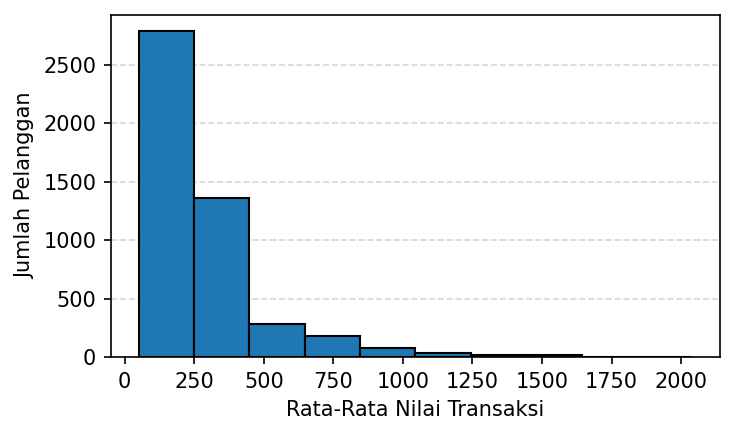

In [ ]:
print("Sebaran Rata-Rata Nilai Transaksi Pelanggan per Pesanan dalam 12 Bulan Terakhir")

plt.figure(figsize=(5,3), dpi=150)
plt.hist(df["avg_order"], bins=10, edgecolor="black")

ax = plt.gca()
ax.set_axisbelow(True)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)

plt.xlabel("Rata-Rata Nilai Transaksi")
plt.ylabel("Jumlah Pelanggan")
plt.tight_layout()
plt.show()

### Bivariat

Numerik vs Kategorik

Sebaran Jumlah Pesanan yang Berhasil Diselesaikan dalam 12 Bulan Terakhir Berdasarkan Respons Pelanggan


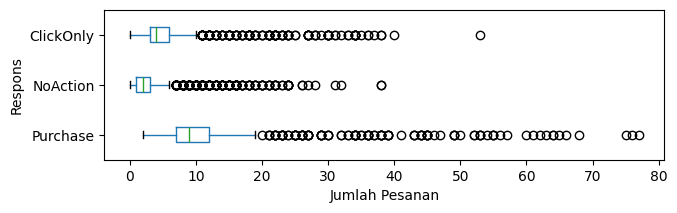

In [ ]:
print("Sebaran Jumlah Pesanan yang Berhasil Diselesaikan dalam 12 Bulan Terakhir Berdasarkan Respons Pelanggan")

fig, ax = plt.subplots(figsize=(7, 2), dpi=100)
df.boxplot(column="past", by="response", grid=False, vert=False, ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Jumlah Pesanan")
ax.set_ylabel("Respons")
ax.set_title("")
fig.suptitle("")
plt.show()

Kategorik vs Kategorik

Perbandingan Jumlah Pelanggan Berdasarkan Respons dan Tipe Wilayah Domisili


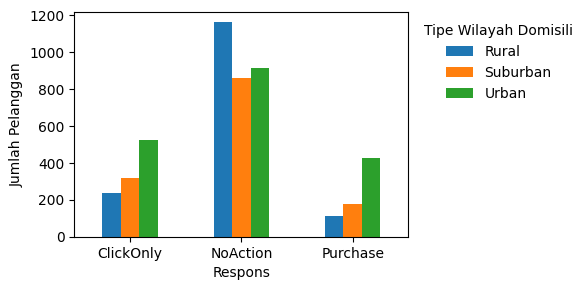

In [ ]:
print("Perbandingan Jumlah Pelanggan Berdasarkan Respons dan Tipe Wilayah Domisili")

pd.crosstab(df["response"], df["region"]).plot(kind="bar", figsize=(6, 3), rot=0)
plt.xlabel("Respons")
plt.ylabel("Jumlah Pelanggan")
plt.legend(title="Tipe Wilayah Domisili", bbox_to_anchor=(1.01, 1),
    loc="upper left", frameon=False
)
plt.tight_layout()
plt.show()

# PREPROCESSING

## Preprocessing Awal

### Missing Value

In [ ]:
print('Total Missing Value')
print(df.isnull().sum())

Total Missing Value
past         492
avg_order    493
opens        492
mobile       486
promo        536
loyalty      462
region       511
category     513
response       0
dtype: int64


In [ ]:
df_lengkap = df.copy()

Jika terdapat missing value pada data, maka terdapat dua opsi untuk menanganinya:


1. Imputasi pada sel data yang kosong dengan suatu nilai (misal: mean/median/modus) pada kolom yang mengandung missing value

In [ ]:
# # 1. Contoh penanganan missing value menggunakan rata-rata
col_with_mis_val = ['past', 'avg_order', 'opens']
for col in col_with_mis_val:
  df_lengkap[col] = df_lengkap[col].fillna(df_lengkap[col].mean())

2. Menghapus baris yang mengandung missing value

In [ ]:
# 2. Contoh penanganan missing value dengan menghapus baris yang mengandung missing value
df_lengkap = df_lengkap.dropna(axis=0)

In [ ]:
print('Total Missing Value')
print(df_lengkap.isnull().sum())

Total Missing Value
past         0
avg_order    0
opens        0
mobile       0
promo        0
loyalty      0
region       0
category     0
response     0
dtype: int64


### Outlier

In [ ]:
def cek_outlier(df, figsize=(4, 1), dpi=150):
    kolom = df.select_dtypes(include=[np.number]).columns
    if len(kolom) == 0:
        print("Tidak ada kolom numerik.")
        return

    df_checked = df[kolom]
    df_checked.plot(
        kind="box",
        subplots=True,
        layout=(len(kolom), 1),
        figsize=(figsize[0], len(kolom) * figsize[1]),
        sharex=False,
        vert=False,
    )

    fig = plt.gcf()
    fig.set_dpi(dpi)
    fig.subplots_adjust(hspace=0.6)

    plt.show()

Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier


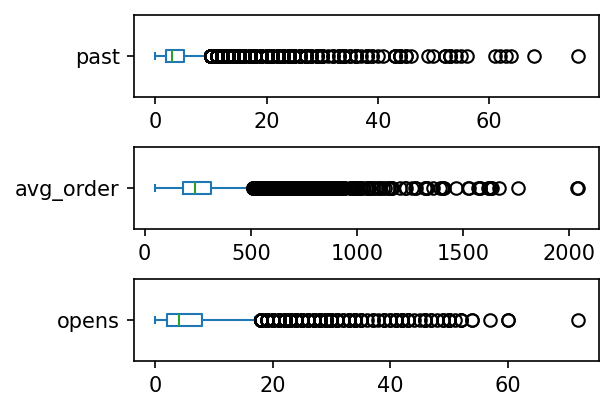

In [ ]:
print("Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier")
cek_outlier(df_lengkap)

Hapus outlier (hanya gunakan jika diperlukan)

In [ ]:
def hapus_outlier(df, kolom=None, max_iter=1):
    kolom = df.select_dtypes(include=[np.number]).columns

    df_clean = df.copy()
    for i in range(max_iter):
        before = df_clean.shape[0]

        mask = pd.Series(True, index=df_clean.index)
        for c in kolom:
            Q1, Q3 = df_clean[c].quantile([0.25, 0.75])
            IQR = Q3 - Q1
            mask &= df_clean[c].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

        df_clean = df_clean[mask]
        after = df_clean.shape[0]

        if before == after:  # berhenti kalau tidak ada perubahan
            break
        print(f'Iterasi {i+1}: {before} -> {after} sampel')

    return df_clean

In [ ]:
df_bersih = df_lengkap.copy()
df_bersih = hapus_outlier(df_bersih, max_iter=10)
print()
df_bersih.info()

Iterasi 1: 3198 -> 2662 sampel
Iterasi 2: 2662 -> 2576 sampel
Iterasi 3: 2576 -> 2520 sampel
Iterasi 4: 2520 -> 2514 sampel
Iterasi 5: 2514 -> 2511 sampel

<class 'pandas.core.frame.DataFrame'>
Index: 2511 entries, 0 to 5249
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   past       2511 non-null   float64
 1   avg_order  2511 non-null   float64
 2   opens      2511 non-null   float64
 3   mobile     2511 non-null   object 
 4   promo      2511 non-null   object 
 5   loyalty    2511 non-null   object 
 6   region     2511 non-null   object 
 7   category   2511 non-null   object 
 8   response   2511 non-null   object 
dtypes: float64(3), object(6)
memory usage: 196.2+ KB


Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier


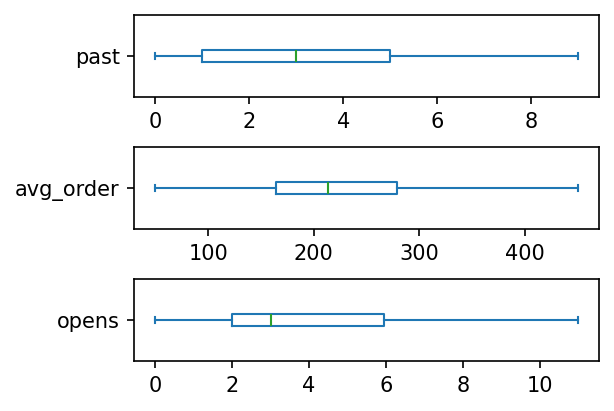

In [ ]:
print("Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier")
cek_outlier(df_bersih)

### Data Duplikat

In [ ]:
print(df_bersih.duplicated().sum(), 'baris terduplikat')
display(df_bersih[df_bersih.duplicated()].head())

47 baris terduplikat


,past,avg_order,opens,mobile,promo,loyalty,region,category,response
427,2.0,110.58,3.0,0,Yes,0,Rural,Groceries,NoAction
746,2.0,324.62,9.0,1,No,0,Urban,Fashion,ClickOnly
1401,6.0,172.52,5.0,0,Yes,0,Rural,Fashion,ClickOnly
2234,3.0,161.16,2.0,0,No,0,Suburban,Groceries,NoAction
2293,2.0,228.16,4.0,1,No,0,Suburban,Fashion,ClickOnly


Hapus data yang terduplikat

In [ ]:
df_siap = df_bersih.copy()
df_siap.drop_duplicates(inplace=True)
print(df_siap.duplicated().sum(), 'baris terduplikat\n')
df_siap.info()

0 baris terduplikat

<class 'pandas.core.frame.DataFrame'>
Index: 2464 entries, 0 to 5249
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   past       2464 non-null   float64
 1   avg_order  2464 non-null   float64
 2   opens      2464 non-null   float64
 3   mobile     2464 non-null   object 
 4   promo      2464 non-null   object 
 5   loyalty    2464 non-null   object 
 6   region     2464 non-null   object 
 7   category   2464 non-null   object 
 8   response   2464 non-null   object 
dtypes: float64(3), object(6)
memory usage: 192.5+ KB


## Splitting Data

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Pisahkan X dan y
col_y = 'response'
X = df_siap.drop(columns=col_y)
y = df_siap[col_y]
labels = np.unique(y)

print('Variabel prediktor:', ', '.join(X.columns.values))
print('Variabel respons/target:', f'{col_y} ({', '.join(labels)})')

Variabel prediktor: past, avg_order, opens, mobile, promo, loyalty, region, category
Variabel respons/target: response (ClickOnly, NoAction, Purchase)


In [ ]:
# Split train (80%) dan test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

print("Ukuran data train:", X_train.shape[0], 'baris')
print("Ukuran data test :", X_test.shape[0], 'baris')

Ukuran data train: 1971 baris
Ukuran data test : 493 baris


## Preprocessing Lanjutan

### One-Hot Encoding (untuk kategorikal)

In [ ]:
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns

X_train_dum = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = X_test_dum.reindex(columns=X_train_dum.columns, fill_value=0)
X_train_dum.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1971 entries, 3597 to 2773
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   past                1971 non-null   float64
 1   avg_order           1971 non-null   float64
 2   opens               1971 non-null   float64
 3   mobile_1            1971 non-null   uint8  
 4   promo_Yes           1971 non-null   uint8  
 5   loyalty_1           1971 non-null   uint8  
 6   region_Suburban     1971 non-null   uint8  
 7   region_Urban        1971 non-null   uint8  
 8   category_Fashion    1971 non-null   uint8  
 9   category_Groceries  1971 non-null   uint8  
 10  category_Mixed      1971 non-null   uint8  
dtypes: float64(3), uint8(8)
memory usage: 77.0 KB


### Standardisasi (untuk numerik)

**Catatan:**
* Jika terdapat variabel prediktor bertipe numerik pada suatu kasus klasifikasi, direkomendasikan untuk menstandardisasi variabel tersebut (mean=0, std=1) pada data training (data testing menyesuaikan) pada beberapa model.
* Model yang mengharuskan hal tersebut antara lain: logistic regression, SVM, k-NN, hingga neural network; sedangkan model-model berbasis pohon (decision tree, random forest) dan boosting (gradient boosting, XGboost, LightGBM) tidak terlalu mempermasalahkan apakah variabel tersebut distandardisasi ataupun tidak.
* Pada praktikum ini, digunakan data yang variabel numeriknya telah distandardsasi agar meminimalkan kesalahan penggunaan data antarmodel serta memastikan perbandingan metrik evaluasi antarmodel lebih adil pada bagian akhir.

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = X_train.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()
scaler.fit(X_train_dum[num_cols])

X_train_std = X_train_dum.copy()
X_test_std  = X_test_dum.copy()
X_train_std[num_cols] = scaler.transform(X_train_dum[num_cols])
X_test_std[num_cols]  = scaler.transform(X_test_dum[num_cols])

In [ ]:
stats_train = pd.DataFrame({
    "mean_before": X_train_dum[num_cols].mean(),
    "std_before":  X_train_dum[num_cols].std(ddof=0),
    "mean_after":  X_train_std[num_cols].mean(),
    "std_after":   X_train_std[num_cols].std(ddof=0),
}).round(3)

# Cek hasil scaling pada data training
stats_train

,mean_before,std_before,mean_after,std_after
past,3.031,2.117,0.0,1.0
avg_order,221.904,75.881,-0.0,1.0
opens,3.900,2.881,0.0,1.0


# RESAMPLING

In [ ]:
def compare_resampling(y_before, y_after):
  df = pd.DataFrame({
    "before": y_before.value_counts(),
    "after": y_after.value_counts(),
  }).fillna(0).astype(int)
  df.loc["Total"] = df.sum()
  return df

## Undersampling

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

In [ ]:
under = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = under.fit_resample(X_train_std, y_train)
compare_resampling(y_train, y_train_under)

,before,after
response,,
ClickOnly,448,157
NoAction,1366,157
Purchase,157,157
Total,1971,471


## Oversampling

In [ ]:
from imblearn.over_sampling import RandomOverSampler

In [ ]:
over = RandomOverSampler(random_state=42)
X_train_over, y_train_over = over.fit_resample(X_train_std, y_train)
compare_resampling(y_train, y_train_over)

,before,after
response,,
NoAction,1366,1366
ClickOnly,448,1366
Purchase,157,1366
Total,1971,4098


## SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
smote = RandomOverSampler(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_std, y_train)
compare_resampling(y_train, y_train_smote)

,before,after
response,,
NoAction,1366,1366
ClickOnly,448,1366
Purchase,157,1366
Total,1971,4098


# KLASIFIKASI

## Persiapan

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

In [ ]:
def get_sen_spe(cm):
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - (tp + fn + fp)

    # handle pembagian 0
    with np.errstate(divide='ignore', invalid='ignore'):
        sensitivity = np.where(tp + fn > 0, tp / (tp + fn), np.nan)
        specificity = np.where(tn + fp > 0, tn / (tn + fp), np.nan)

    return sensitivity, specificity

In [ ]:
def visualize_confusion_matrix(cm):
  fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
  disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

  ax.set_xlabel("Kelas Prediksi")
  ax.set_ylabel("Kelas Aktual")

  plt.tight_layout()
  plt.show()

In [ ]:
resampling_scenarios = ['Tanpa Resampling', 'Undersampling', 'Oversampling', 'SMOTE']
all_X_train = [X_train_std, X_train_under, X_train_over, X_train_smote]
all_y_train = [y_train, y_train_under, y_train_over, y_train_smote]

## k-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

Membuat, melatih, dan mengevaluasi model

In [ ]:
all_knn_model = []
all_knn_train_acc = []
all_knn_test_acc = []
all_knn_cm = []
all_knn_sen = []
all_knn_spe = []

for scenario, X_train, y_train in zip(resampling_scenarios, all_X_train, all_y_train):
    # buat & latih model
    model = KNeighborsClassifier()
    model.fit(X_train, y_train)

    # prediksi
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test_std)

    # akurasi
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test, y_pred_test)

    # confusion matrix + sen/spe
    cm = confusion_matrix(y_test, y_pred_test, labels=labels)
    sen, spe = get_sen_spe(cm)

    # simpan hasil
    all_knn_model.append(model)
    all_knn_train_acc.append(train_acc)
    all_knn_test_acc.append(test_acc)
    all_knn_cm.append(cm)
    all_knn_sen.append(sen)
    all_knn_spe.append(spe)

    print(f'Berhasil melatih dan mengevaluasi model untuk skenario {scenario}.')

Berhasil melatih dan mengevaluasi model untuk skenario Tanpa Resampling.
Berhasil melatih dan mengevaluasi model untuk skenario Undersampling.
Berhasil melatih dan mengevaluasi model untuk skenario Oversampling.
Berhasil melatih dan mengevaluasi model untuk skenario SMOTE.


Menampilkan metrik evaluasi untuk setiap skenario

In [ ]:
df_knn_acc = pd.DataFrame({
    ('Skenario', ''): resampling_scenarios,
    ('Akurasi', 'Test'): all_knn_test_acc,
    ('Akurasi', 'Train'): all_knn_train_acc,
}).sort_values(by=('Akurasi', 'Test'), ascending=False)
df_knn_acc

Skenario   Akurasi          
                         Test     Train
0  Tanpa Resampling  0.884381  0.919330
2      Oversampling  0.837728  0.958760
3             SMOTE  0.837728  0.958760
1     Undersampling  0.819473  0.915074

In [ ]:
df_knn_ss = []
for i, label in enumerate(labels):
  print(f'Jika "{label}" adalah kelas posiif:')
  df_ss = pd.DataFrame({
          'Skenario': resampling_scenarios,
          'Sensitivitas': [sen[i] for sen in all_knn_sen],
          'Spesifisitas': [spe[i] for spe in all_knn_spe],
      }).sort_values(by='Sensitivitas', ascending=False)
  df_knn_ss.append(df_ss)
  display(df_ss)
  print('')

Jika "ClickOnly" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
0,Tanpa Resampling,0.759259,0.927273
2,Oversampling,0.750000,0.870130
3,SMOTE,0.750000,0.870130
1,Undersampling,0.657407,0.877922



Jika "NoAction" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
0,Tanpa Resampling,0.938776,0.873333
2,Oversampling,0.883382,0.893333
3,SMOTE,0.883382,0.893333
1,Undersampling,0.860058,0.926667



Jika "Purchase" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
1,Undersampling,0.904762,0.931264
0,Tanpa Resampling,0.761905,0.977827
2,Oversampling,0.690476,0.968958
3,SMOTE,0.690476,0.968958


Tanpa Resampling:


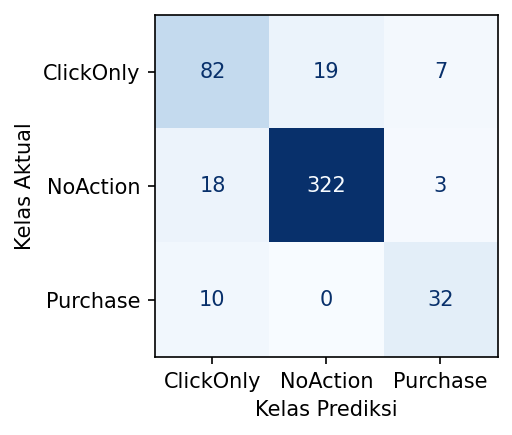


Undersampling:


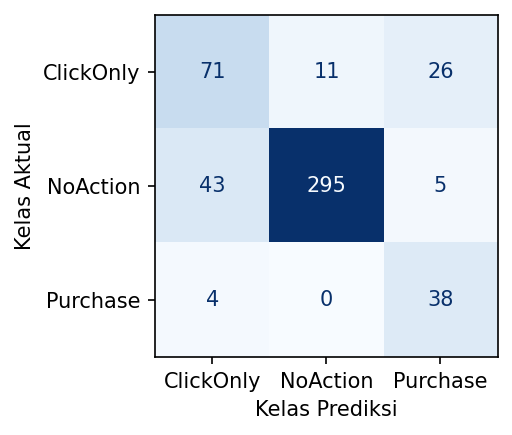


Oversampling:


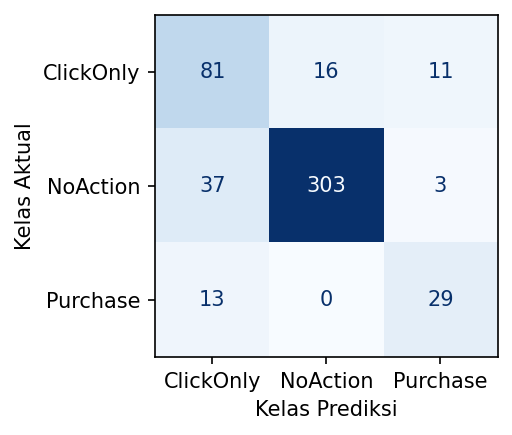


SMOTE:


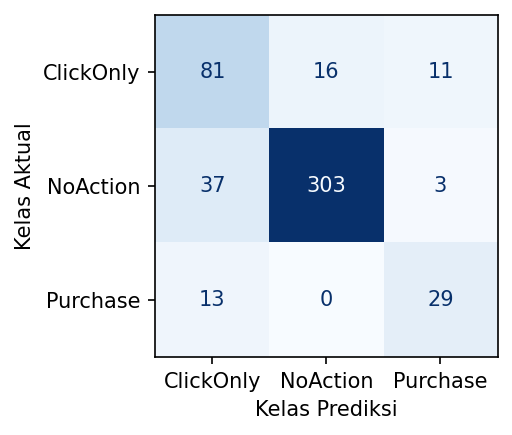

In [ ]:
for scenario, cm in zip(resampling_scenarios, all_knn_cm):
  print(f'{scenario}:')
  visualize_confusion_matrix(cm)
  print('')

## Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

Membuat, melatih, dan mengevaluasi model

In [ ]:
all_dct_model = []
all_dct_train_acc = []
all_dct_test_acc = []
all_dct_cm = []
all_dct_sen = []
all_dct_spe = []

for scenario, X_train, y_train in zip(resampling_scenarios, all_X_train, all_y_train):
    # buat & latih model
    model = DecisionTreeClassifier()
    model.fit(X_train, y_train)

    # prediksi
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test_std)

    # akurasi
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test, y_pred_test)

    # confusion matrix + sen/spe
    cm = confusion_matrix(y_test, y_pred_test, labels=labels)
    sen, spe = get_sen_spe(cm)

    # simpan hasil
    all_dct_model.append(model)
    all_dct_train_acc.append(train_acc)
    all_dct_test_acc.append(test_acc)
    all_dct_cm.append(cm)
    all_dct_sen.append(sen)
    all_dct_spe.append(spe)

    print(f'Berhasil melatih dan mengevaluasi model untuk skenario {scenario}.')

Berhasil melatih dan mengevaluasi model untuk skenario Tanpa Resampling.
Berhasil melatih dan mengevaluasi model untuk skenario Undersampling.
Berhasil melatih dan mengevaluasi model untuk skenario Oversampling.
Berhasil melatih dan mengevaluasi model untuk skenario SMOTE.


Menampilkan metrik evaluasi untuk setiap skenario

In [ ]:
df_dct_acc = pd.DataFrame({
    ('Skenario', ''): resampling_scenarios,
    ('Akurasi', 'Test'): all_dct_test_acc,
    ('Akurasi', 'Train'): all_dct_train_acc,
}).sort_values(by=('Akurasi', 'Test'), ascending=False)
df_dct_acc

Skenario   Akurasi      
                         Test Train
0  Tanpa Resampling  0.860041   1.0
3             SMOTE  0.833671   1.0
2      Oversampling  0.831643   1.0
1     Undersampling  0.803245   1.0

In [ ]:
df_dct_ss = []
for i, label in enumerate(labels):
  print(f'Jika "{label}" adalah kelas posiif:')
  df_ss = pd.DataFrame({
          'Skenario': resampling_scenarios,
          'Sensitivitas': [sen[i] for sen in all_dct_sen],
          'Spesifisitas': [spe[i] for spe in all_dct_spe],
      }).sort_values(by='Sensitivitas', ascending=False)
  df_dct_ss.append(df_ss)
  display(df_ss)
  print('')

Jika "ClickOnly" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
1,Undersampling,0.731481,0.846753
0,Tanpa Resampling,0.675926,0.922078
2,Oversampling,0.648148,0.898701
3,SMOTE,0.638889,0.903896



Jika "NoAction" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
0,Tanpa Resampling,0.932945,0.866667
3,SMOTE,0.915452,0.840000
2,Oversampling,0.909621,0.846667
1,Undersampling,0.830904,0.913333



Jika "Purchase" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
1,Undersampling,0.761905,0.944568
0,Tanpa Resampling,0.738095,0.957871
2,Oversampling,0.666667,0.953437
3,SMOTE,0.666667,0.953437


Tanpa Resampling:


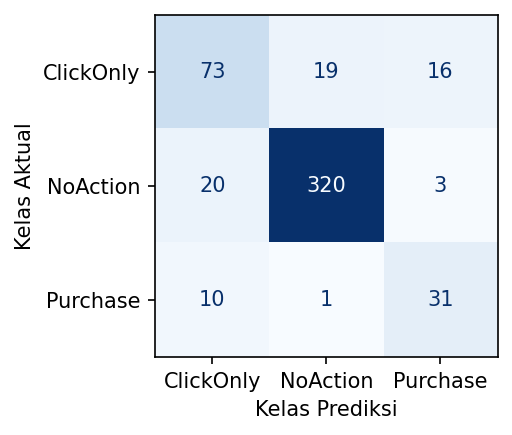


Undersampling:


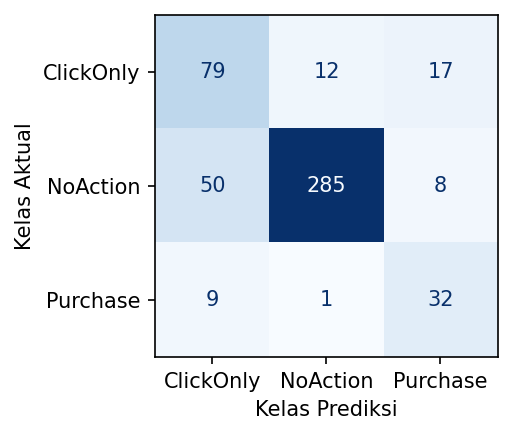


Oversampling:


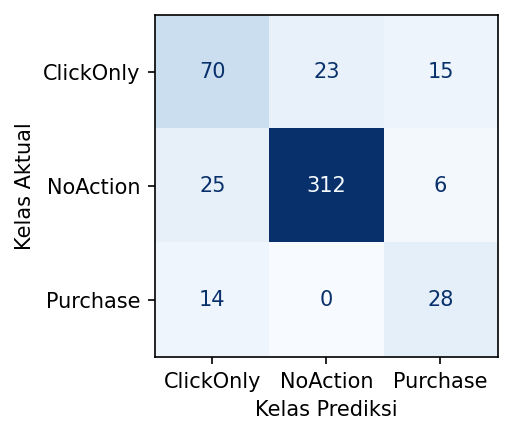


SMOTE:


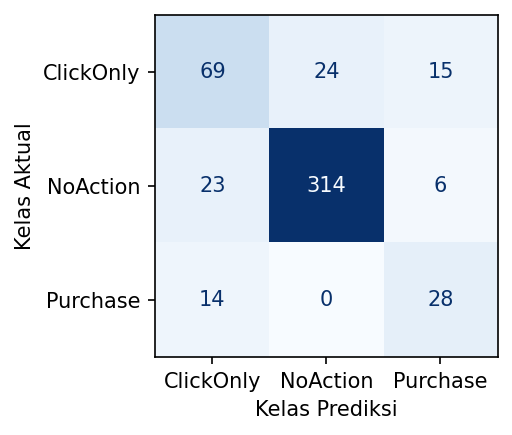

In [ ]:
for scenario, cm in zip(resampling_scenarios, all_dct_cm):
  print(f'{scenario}:')
  visualize_confusion_matrix(cm)
  print('')

## Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC

Membuat, melatih, dan mengevaluasi model

In [ ]:
all_svm_model = []
all_svm_train_acc = []
all_svm_test_acc = []
all_svm_cm = []
all_svm_sen = []
all_svm_spe = []

for scenario, X_train, y_train in zip(resampling_scenarios, all_X_train, all_y_train):
    # buat & latih model
    model = SVC(probability=True) # probability=True agar model bisa menghitung peluang prediksi
    model.fit(X_train, y_train)

    # prediksi
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test_std)

    # akurasi
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test, y_pred_test)

    # confusion matrix + sen/spe
    cm = confusion_matrix(y_test, y_pred_test, labels=labels)
    sen, spe = get_sen_spe(cm)

    # simpan hasil
    all_svm_model.append(model)
    all_svm_train_acc.append(train_acc)
    all_svm_test_acc.append(test_acc)
    all_svm_cm.append(cm)
    all_svm_sen.append(sen)
    all_svm_spe.append(spe)

    print(f'Berhasil melatih dan mengevaluasi model untuk skenario {scenario}.')

Berhasil melatih dan mengevaluasi model untuk skenario Tanpa Resampling.
Berhasil melatih dan mengevaluasi model untuk skenario Undersampling.
Berhasil melatih dan mengevaluasi model untuk skenario Oversampling.
Berhasil melatih dan mengevaluasi model untuk skenario SMOTE.


Menampilkan metrik evaluasi untuk setiap skenario

In [ ]:
df_svm_acc = pd.DataFrame({
    ('Skenario', ''): resampling_scenarios,
    ('Akurasi', 'Test'): all_svm_test_acc,
    ('Akurasi', 'Train'): all_svm_train_acc,
}).sort_values(by=('Akurasi', 'Test'), ascending=False)
df_svm_acc

Skenario   Akurasi          
                         Test     Train
0  Tanpa Resampling  0.888438  0.928463
2      Oversampling  0.872211  0.926306
3             SMOTE  0.872211  0.926306
1     Undersampling  0.862069  0.912951

In [ ]:
df_svm_ss = []
for i, label in enumerate(labels):
  print(f'Jika "{label}" adalah kelas posiif:')
  df_ss = pd.DataFrame({
          'Skenario': resampling_scenarios,
          'Sensitivitas': [sen[i] for sen in all_svm_sen],
          'Spesifisitas': [spe[i] for spe in all_svm_spe],
      }).sort_values(by='Sensitivitas', ascending=False)
  df_svm_ss.append(df_ss)
  display(df_ss)
  print('')

Jika "ClickOnly" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
3,SMOTE,0.787037,0.903896
2,Oversampling,0.787037,0.903896
0,Tanpa Resampling,0.768519,0.927273
1,Undersampling,0.759259,0.901299



Jika "NoAction" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
0,Tanpa Resampling,0.935860,0.873333
2,Oversampling,0.900875,0.940000
3,SMOTE,0.900875,0.940000
1,Undersampling,0.892128,0.933333



Jika "Purchase" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
1,Undersampling,0.880952,0.955654
2,Oversampling,0.857143,0.962306
3,SMOTE,0.857143,0.962306
0,Tanpa Resampling,0.809524,0.982262


Tanpa Resampling:


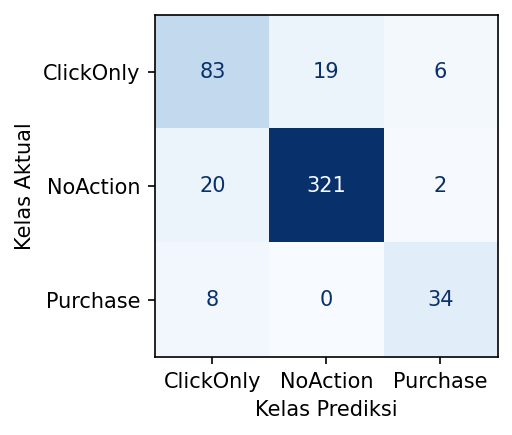


Undersampling:


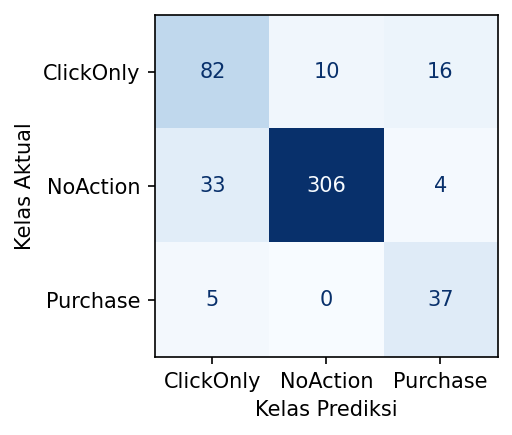


Oversampling:


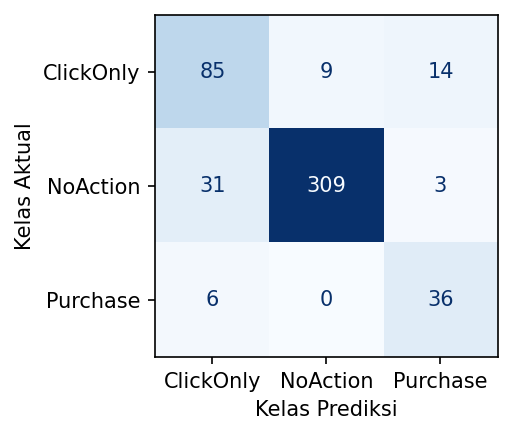


SMOTE:


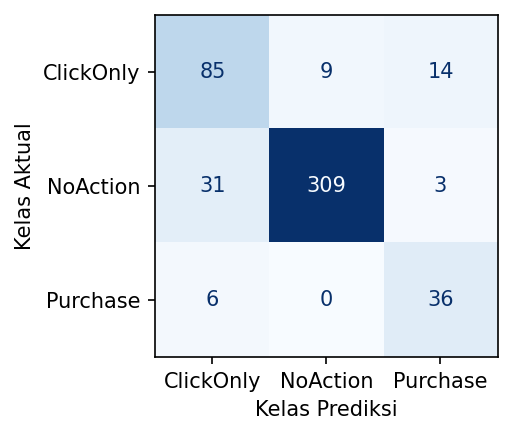

In [ ]:
for scenario, cm in zip(resampling_scenarios, all_svm_cm):
  print(f'{scenario}:')
  visualize_confusion_matrix(cm)
  print('')

## Random Forest Classification

Random forest adalah salah satu model klasifikasi yang menerapkan algoritma *bagging*.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

Membuat, melatih, dan mengevaluasi model

In [ ]:
all_rfc_model = []
all_rfc_train_acc = []
all_rfc_test_acc = []
all_rfc_cm = []
all_rfc_sen = []
all_rfc_spe = []

for scenario, X_train, y_train in zip(resampling_scenarios, all_X_train, all_y_train):
    # buat & latih model
    model = RandomForestClassifier()
    model.fit(X_train, y_train)

    # prediksi
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test_std)

    # akurasi
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test, y_pred_test)

    # confusion matrix + sen/spe
    cm = confusion_matrix(y_test, y_pred_test, labels=labels)
    sen, spe = get_sen_spe(cm)

    # simpan hasil
    all_rfc_model.append(model)
    all_rfc_train_acc.append(train_acc)
    all_rfc_test_acc.append(test_acc)
    all_rfc_cm.append(cm)
    all_rfc_sen.append(sen)
    all_rfc_spe.append(spe)

    print(f'Berhasil melatih dan mengevaluasi model untuk skenario {scenario}.')

Berhasil melatih dan mengevaluasi model untuk skenario Tanpa Resampling.
Berhasil melatih dan mengevaluasi model untuk skenario Undersampling.
Berhasil melatih dan mengevaluasi model untuk skenario Oversampling.
Berhasil melatih dan mengevaluasi model untuk skenario SMOTE.


Menampilkan metrik evaluasi untuk setiap skenario

In [ ]:
df_rfc_acc = pd.DataFrame({
    ('Skenario', ''): resampling_scenarios,
    ('Akurasi', 'Test'): all_rfc_test_acc,
    ('Akurasi', 'Train'): all_rfc_train_acc,
}).sort_values(by=('Akurasi', 'Test'), ascending=False)
df_rfc_acc

Skenario   Akurasi      
                         Test Train
0  Tanpa Resampling  0.886410   1.0
3             SMOTE  0.886410   1.0
2      Oversampling  0.880325   1.0
1     Undersampling  0.845842   1.0

In [ ]:
df_rfc_ss = []
for i, label in enumerate(labels):
  print(f'Jika "{label}" adalah kelas posiif:')
  df_ss = pd.DataFrame({
          'Skenario': resampling_scenarios,
          'Sensitivitas': [sen[i] for sen in all_rfc_sen],
          'Spesifisitas': [spe[i] for spe in all_rfc_spe],
      }).sort_values(by='Sensitivitas', ascending=False)
  df_rfc_ss.append(df_ss)
  display(df_ss)
  print('')

Jika "ClickOnly" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
3,SMOTE,0.768519,0.924675
2,Oversampling,0.768519,0.916883
1,Undersampling,0.731481,0.888312
0,Tanpa Resampling,0.731481,0.932468



Jika "NoAction" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
0,Tanpa Resampling,0.950437,0.860000
3,SMOTE,0.935860,0.886667
2,Oversampling,0.927114,0.873333
1,Undersampling,0.880466,0.933333



Jika "Purchase" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
1,Undersampling,0.857143,0.949002
2,Oversampling,0.785714,0.982262
3,SMOTE,0.785714,0.977827
0,Tanpa Resampling,0.761905,0.980044


Tanpa Resampling:


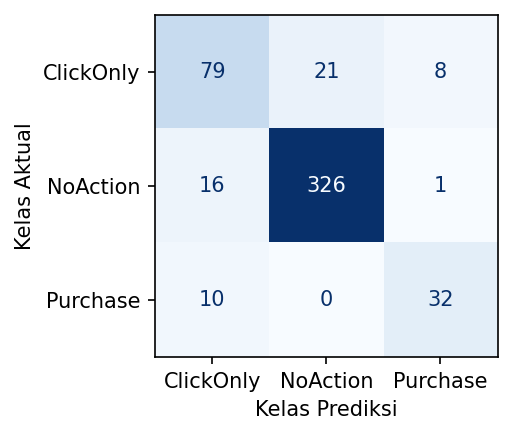


Undersampling:


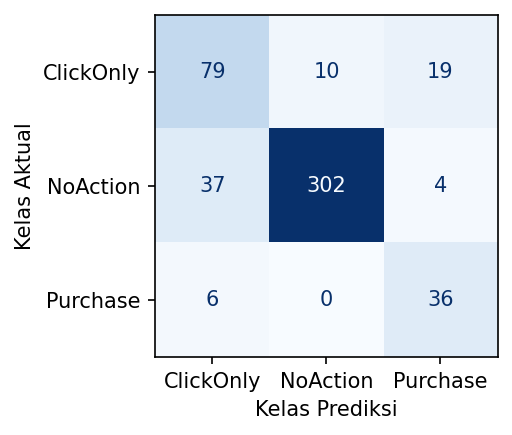


Oversampling:


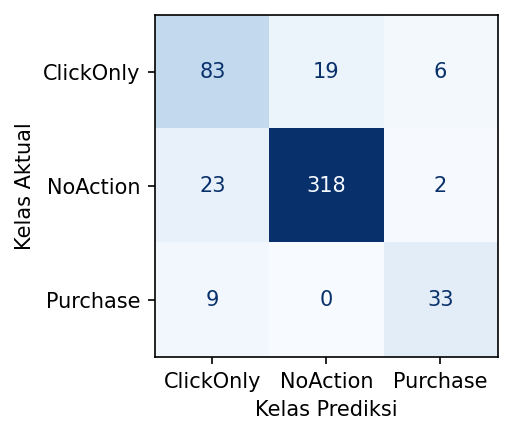


SMOTE:


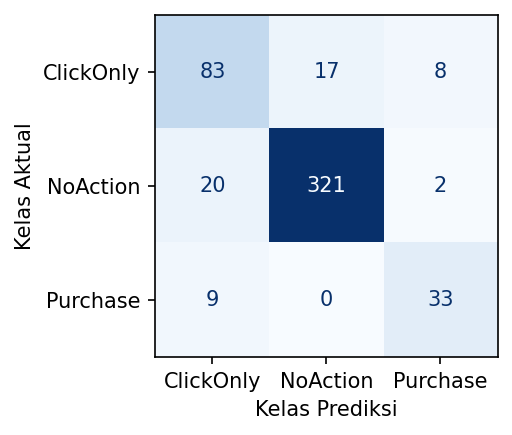

In [ ]:
for scenario, cm in zip(resampling_scenarios, all_rfc_cm):
  print(f'{scenario}:')
  visualize_confusion_matrix(cm)
  print('')

## Gradient Boosting

Gradient boosting adalah salah satu model klasifikasi yang menerapkan algoritma *boosting*.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

Membuat, melatih, dan mengevaluasi model

In [ ]:
all_gbt_model = []
all_gbt_train_acc = []
all_gbt_test_acc = []
all_gbt_cm = []
all_gbt_sen = []
all_gbt_spe = []

for scenario, X_train, y_train in zip(resampling_scenarios, all_X_train, all_y_train):
    # buat & latih model
    model = GradientBoostingClassifier()
    model.fit(X_train, y_train)

    # prediksi
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test_std)

    # akurasi
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test, y_pred_test)

    # confusion matrix + sen/spe
    cm = confusion_matrix(y_test, y_pred_test, labels=labels)
    sen, spe = get_sen_spe(cm)

    # simpan hasil
    all_gbt_model.append(model)
    all_gbt_train_acc.append(train_acc)
    all_gbt_test_acc.append(test_acc)
    all_gbt_cm.append(cm)
    all_gbt_sen.append(sen)
    all_gbt_spe.append(spe)

    print(f'Berhasil melatih dan mengevaluasi model untuk skenario {scenario}.')

Berhasil melatih dan mengevaluasi model untuk skenario Tanpa Resampling.
Berhasil melatih dan mengevaluasi model untuk skenario Undersampling.
Berhasil melatih dan mengevaluasi model untuk skenario Oversampling.
Berhasil melatih dan mengevaluasi model untuk skenario SMOTE.


Menampilkan metrik evaluasi untuk setiap skenario

In [ ]:
df_gbt_acc = pd.DataFrame({
    ('Skenario', ''): resampling_scenarios,
    ('Akurasi', 'Test'): all_gbt_test_acc,
    ('Akurasi', 'Train'): all_gbt_train_acc,
}).sort_values(by=('Akurasi', 'Test'), ascending=False)
df_gbt_acc

Skenario   Akurasi          
                         Test     Train
0  Tanpa Resampling  0.892495  0.958397
3             SMOTE  0.892495  0.956320
2      Oversampling  0.890467  0.956320
1     Undersampling  0.851927  0.991507

In [ ]:
df_gbt_ss = []
for i, label in enumerate(labels):
  print(f'Jika "{label}" adalah kelas posiif:')
  df_ss = pd.DataFrame({
          'Skenario': resampling_scenarios,
          'Sensitivitas': [sen[i] for sen in all_gbt_sen],
          'Spesifisitas': [spe[i] for spe in all_gbt_spe],
      }).sort_values(by='Sensitivitas', ascending=False)
  df_gbt_ss.append(df_ss)
  display(df_ss)
  print('')

Jika "ClickOnly" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
3,SMOTE,0.796296,0.929870
2,Oversampling,0.796296,0.927273
1,Undersampling,0.777778,0.888312
0,Tanpa Resampling,0.740741,0.940260



Jika "NoAction" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
0,Tanpa Resampling,0.953353,0.880000
3,SMOTE,0.927114,0.933333
2,Oversampling,0.924198,0.933333
1,Undersampling,0.877551,0.946667



Jika "Purchase" adalah kelas posiif:


,Skenario,Sensitivitas,Spesifisitas
3,SMOTE,0.857143,0.964523
2,Oversampling,0.857143,0.964523
1,Undersampling,0.833333,0.951220
0,Tanpa Resampling,0.785714,0.973392


Tanpa Resampling:


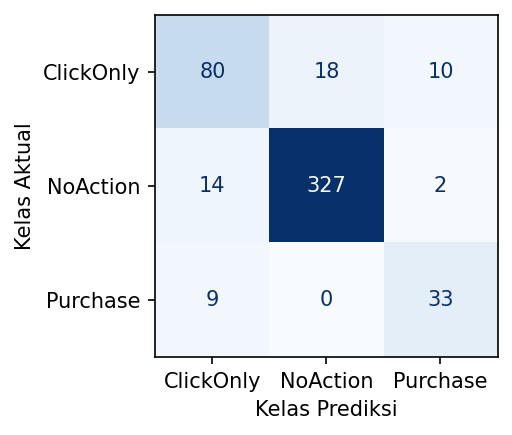


Undersampling:


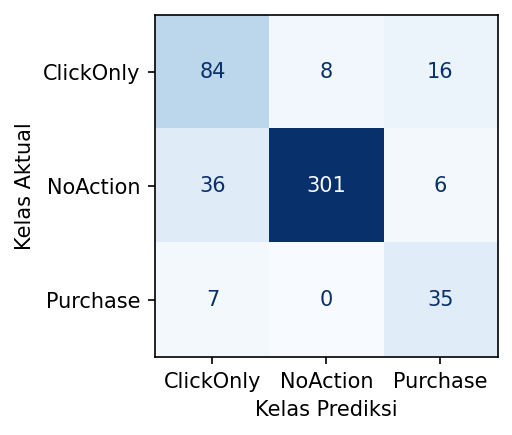


Oversampling:


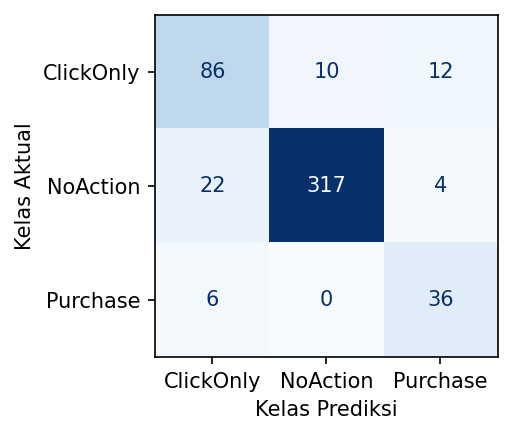


SMOTE:


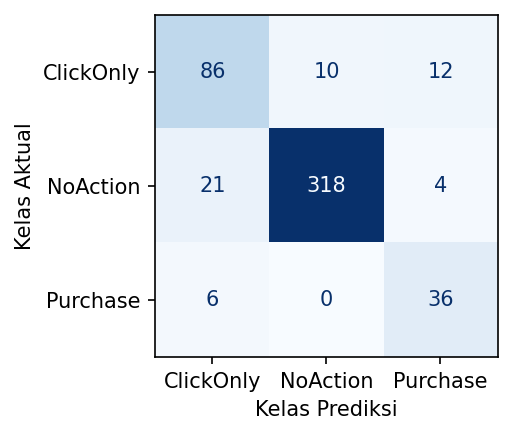

In [ ]:
for scenario, cm in zip(resampling_scenarios, all_gbt_cm):
  print(f'{scenario}:')
  visualize_confusion_matrix(cm)
  print('')

# PERBANDINGAN METRIK EVALUASI

Berdasarkan akurasi

In [ ]:
model_names = ['k-NN', 'Decision Tree', 'SVM', 'Random Forest', 'Gradient Boosting']
all_df_acc = [df_knn_acc, df_dct_acc, df_svm_acc, df_rfc_acc, df_gbt_acc]

all_df_acc_with_model = [
    df.assign(Model=model_name)
    for df, model_name in zip(all_df_acc, model_names)
]

df_comparison_acc = pd.concat(all_df_acc_with_model, ignore_index=True)
cols = [('Model', '')] + [c for c in df_comparison_acc.columns if c != ('Model', '')]
df_comparison_acc = df_comparison_acc[cols]
df_comparison_acc = df_comparison_acc.sort_values(by=('Akurasi', 'Test'), ascending=False)
df_comparison_acc = df_comparison_acc.reset_index(drop=True)
df_comparison_acc

Model          Skenario   Akurasi          
                                             Test     Train
0   Gradient Boosting             SMOTE  0.892495  0.956320
1   Gradient Boosting  Tanpa Resampling  0.892495  0.958397
2   Gradient Boosting      Oversampling  0.890467  0.956320
3                 SVM  Tanpa Resampling  0.888438  0.928463
4       Random Forest  Tanpa Resampling  0.886410  1.000000
5       Random Forest             SMOTE  0.886410  1.000000
6                k-NN  Tanpa Resampling  0.884381  0.919330
7       Random Forest      Oversampling  0.880325  1.000000
8                 SVM             SMOTE  0.872211  0.926306
9                 SVM      Oversampling  0.872211  0.926306
10                SVM     Undersampling  0.862069  0.912951
11      Decision Tree  Tanpa Resampling  0.860041  1.000000
12  Gradient Boosting     Undersampling  0.851927  0.991507
13      Random Forest     Undersampling  0.845842  1.000000
14               k-NN      Oversampling  0.837728  0.958760
15               k-NN             SMOTE  0.837728  0.958760
16      Decision Tree             SMOTE  0.833671  1.000000
17      Decision Tree      Oversampling  0.831643  1.000000
18               k-NN     Undersampling  0.819473  0.915074
19      Decision Tree     Undersampling  0.803245  1.000000

In [ ]:
for i, label in enumerate(labels):
  model_names = ['k-NN', 'Decision Tree', 'SVM', 'Random Forest', 'Gradient Boosting']
  all_df_ss = [df_knn_ss[i], df_dct_ss[i], df_svm_ss[i], df_rfc_ss[i], df_gbt_ss[i]]

  all_df_ss_with_model = [
      df.assign(Model=model_name)
      for df, model_name in zip(all_df_ss, model_names)
  ]

  df_comparison_ss = pd.concat(all_df_ss_with_model, ignore_index=True)
  cols = ['Model'] + [c for c in df_comparison_ss.columns if c != 'Model']
  df_comparison_ss = df_comparison_ss[cols]
  df_comparison_ss = df_comparison_ss.sort_values(by='Sensitivitas', ascending=False)
  df_comparison_ss = df_comparison_ss.reset_index(drop=True)

  print(f'Jika "{label}" adalah kelas posiif:')
  display(df_comparison_ss)
  print('')

Jika "ClickOnly" adalah kelas posiif:


,Model,Skenario,Sensitivitas,Spesifisitas
0,Gradient Boosting,Oversampling,0.796296,0.927273
1,Gradient Boosting,SMOTE,0.796296,0.929870
2,SVM,SMOTE,0.787037,0.903896
3,SVM,Oversampling,0.787037,0.903896
4,Gradient Boosting,Undersampling,0.777778,0.888312
5,Random Forest,SMOTE,0.768519,0.924675
6,SVM,Tanpa Resampling,0.768519,0.927273
7,Random Forest,Oversampling,0.768519,0.916883
8,SVM,Undersampling,0.759259,0.901299
9,k-NN,Tanpa Resampling,0.759259,0.927273



Jika "NoAction" adalah kelas posiif:


,Model,Skenario,Sensitivitas,Spesifisitas
0,Gradient Boosting,Tanpa Resampling,0.953353,0.880000
1,Random Forest,Tanpa Resampling,0.950437,0.860000
2,k-NN,Tanpa Resampling,0.938776,0.873333
3,SVM,Tanpa Resampling,0.935860,0.873333
4,Random Forest,SMOTE,0.935860,0.886667
5,Decision Tree,Tanpa Resampling,0.932945,0.866667
6,Gradient Boosting,SMOTE,0.927114,0.933333
7,Random Forest,Oversampling,0.927114,0.873333
8,Gradient Boosting,Oversampling,0.924198,0.933333
9,Decision Tree,SMOTE,0.915452,0.840000



Jika "Purchase" adalah kelas posiif:


,Model,Skenario,Sensitivitas,Spesifisitas
0,k-NN,Undersampling,0.904762,0.931264
1,SVM,Undersampling,0.880952,0.955654
2,SVM,Oversampling,0.857143,0.962306
3,SVM,SMOTE,0.857143,0.962306
4,Gradient Boosting,SMOTE,0.857143,0.964523
5,Gradient Boosting,Oversampling,0.857143,0.964523
6,Random Forest,Undersampling,0.857143,0.949002
7,Gradient Boosting,Undersampling,0.833333,0.951220
8,SVM,Tanpa Resampling,0.809524,0.982262
9,Random Forest,Oversampling,0.785714,0.982262


# PREDIKSI

Berdasarkan perbandingan akurasi antarmodel untuk setiap skenario, diperoleh model terbaik (akurasi testing tertinggi) adalah **model** ***gradient boosting*** dengan *resampling* berupa **SMOTE.**

In [ ]:
best_model = all_gbt_model[2]
# 0 = tanpa resampling, 1 = under, 2 = over, 3 = smote

Sebagai contoh, dilakukan prediksi kelas klasifikasi terhadap data baru menggunakan model dan penanganan terbaik:

In [ ]:
# Membuat data baru
X_new = pd.DataFrame([
    {
        "past": 18.0,
        "avg_order": 380.0,
        "opens": 25.0,
        "mobile_1": 1,
        "promo_Yes": 1,
        "loyalty_1": 1,
        "region_Suburban": 0,
        "region_Urban": 1,
        "category_Fashion": 0,
        "category_Groceries": 0,
        "category_Mixed": 0,
    },
    {
        "past": 6.0,
        "avg_order": 260.0,
        "opens": 10.0,
        "mobile_1": 1,
        "promo_Yes": 1,
        "loyalty_1": 0,
        "region_Suburban": 1,
        "region_Urban": 0,
        "category_Fashion": 1,
        "category_Groceries": 0,
        "category_Mixed": 0,
    },
    {
        "past": 0.0,
        "avg_order": 100.0,
        "opens": 0.0,
        "mobile_1": 0,
        "promo_Yes": 0,
        "loyalty_1": 0,
        "region_Suburban": 0,
        "region_Urban": 0,
        "category_Fashion": 0,
        "category_Groceries": 1,
        "category_Mixed": 0,
    },
])

# Melakukan prediksi
y_prob_new = best_model.predict_proba(X_new)
y_pred_new = best_model.predict(X_new)

# Menghitung peluang klasifikasi per kelas
prob_cols = [f"prob_{cls}" for cls in best_model.classes_]
df_proba = pd.DataFrame(y_prob_new, columns=prob_cols)

# Menampilkan hasil prediksi
df_hasil = pd.concat([X_new.reset_index(drop=True), df_proba], axis=1)
df_hasil["Prediksi"] = y_pred_new
df_hasil

,past,avg_order,opens,mobile_1,promo_Yes,loyalty_1,region_Suburban,region_Urban,category_Fashion,category_Groceries,category_Mixed,prob_ClickOnly,prob_NoAction,prob_Purchase,Prediksi
0,18.0,380.0,25.0,1,1,1,0,1,0,0,0,0.001340,0.031536,0.967124,Purchase
1,6.0,260.0,10.0,1,1,0,1,0,1,0,0,0.003782,0.112196,0.884022,Purchase
2,0.0,100.0,0.0,0,0,0,0,0,0,1,0,0.001081,0.997622,0.001298,NoAction
